In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("creditcard.csv")
df.columns = df.columns.str.lower()
df.insert(0, "txn_id", range(1, len(df) + 1))
os.makedirs("images", exist_ok=True)
print(df.shape)
df.head()

Saving creditcard.csv to creditcard (1).csv
(284807, 32)


,txn_id,time,v1,v2,v3,v4,v5,v6,v7,v8,...,v21,v22,v23,v24,v25,v26,v27,v28,amount,class
0,1,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,2,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,3,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,4,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,5,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Duplicate del


In [5]:
feature_cols = [c for c in df.columns if c != "txn_id"]
before = len(df)
df = df.drop_duplicates(subset=feature_cols).reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows. Remaining: {len(df)}")

Removed 1081 duplicate rows. Remaining: 283726


How rare fraud

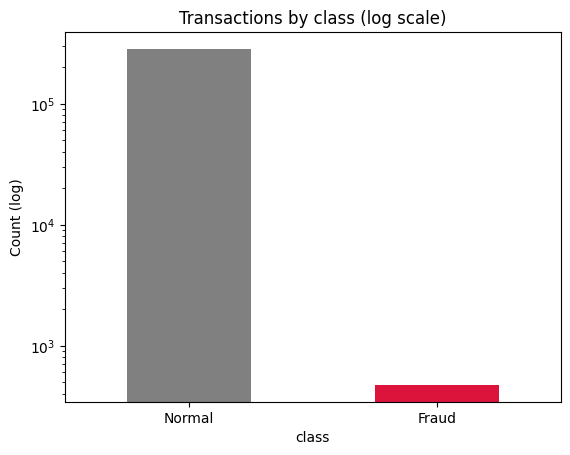

In [6]:
import os
os.makedirs("images", exist_ok=True)

ax = df["class"].value_counts().rename({0: "Normal", 1: "Fraud"}).plot(kind="bar", logy=True, color=["gray", "crimson"])
ax.set_title("Transactions by class (log scale)")
ax.set_ylabel("Count (log)")
plt.xticks(rotation=0)
plt.savefig("images/01_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()


```
Transaction amount```



/tmp/ipykernel_1124/3629610271.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=plot_df, x="label", y="amount", palette=["gray", "crimson"])


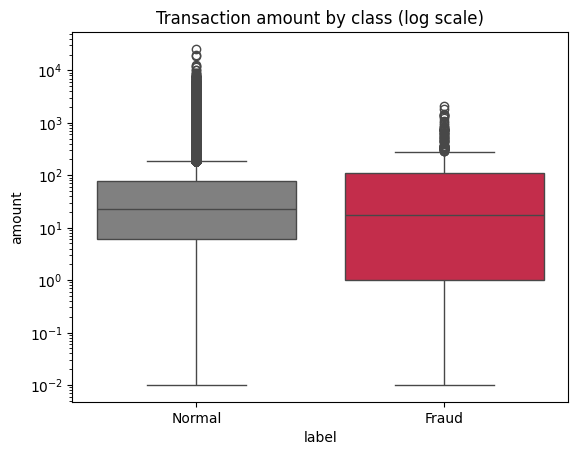

In [7]:
plot_df = df[df["amount"] > 0].copy()
plot_df["label"] = plot_df["class"].map({0: "Normal", 1: "Fraud"})
ax = sns.boxplot(data=plot_df, x="label", y="amount", palette=["gray", "crimson"])
ax.set_yscale("log")
ax.set_title("Transaction amount by class (log scale)")
plt.savefig("images/02_amount_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

Hourly

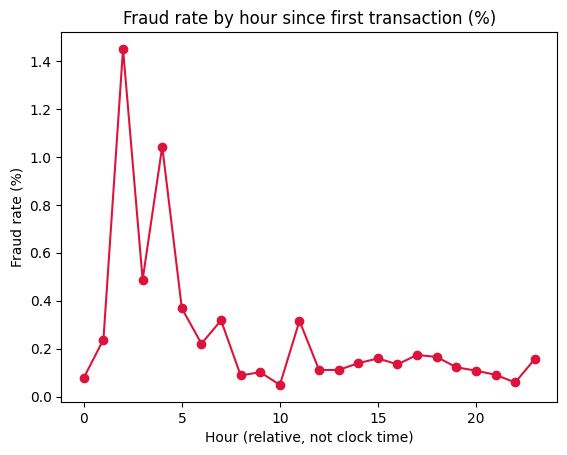

In [10]:
df["hour"] = (df["time"] // 3600 % 24).astype(int)
rate = df.groupby("hour")["class"].mean() * 100
ax = rate.plot(marker="o", color="crimson")
ax.set_title("Fraud rate by hour since first transaction (%)")
ax.set_xlabel("Hour (relative, not clock time)")
ax.set_ylabel("Fraud rate (%)")
plt.savefig("images/03_fraud_rate_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

high Releation of fraud

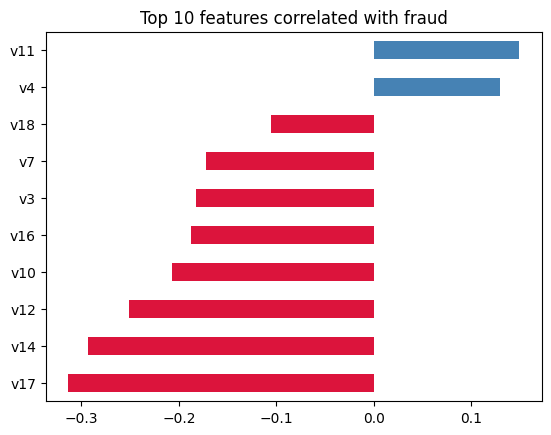

In [11]:
corr = df.drop(columns=["txn_id", "hour"]).corr()["class"].drop("class")
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(10)
ax = top.sort_values().plot(kind="barh", color=["crimson" if v < 0 else "steelblue" for v in top.sort_values()])
ax.set_title("Top 10 features correlated with fraud")
plt.savefig("images/04_top_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

Train / Testing spllit

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["class", "txn_id", "hour"])
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

X_train, X_test = X_train.copy(), X_test.copy()
scaler = StandardScaler()
X_train[["time", "amount"]] = scaler.fit_transform(X_train[["time", "amount"]])
X_test[["time", "amount"]] = scaler.transform(X_test[["time", "amount"]])

print("Fraud share — train:", round(y_train.mean() * 100, 3), "% | test:", round(y_test.mean() * 100, 3), "%")

Fraud share — train: 0.167 % | test: 0.167 %


Modle train

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

Accuracy and precision

In [16]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score)

print("Baseline accuracy if we call everything 'normal':",
      round((1 - y_test.mean()) * 100, 2), "%\n")

for name, model in [("Logistic Regression", lr), ("Random Forest", rf)]:
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(f"=== {name} ===")
    print("PR-AUC:", round(average_precision_score(y_test, proba), 3))
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=3,
                                target_names=["Normal", "Fraud"]))

Baseline accuracy if we call everything 'normal': 99.83 %

=== Logistic Regression ===
PR-AUC: 0.688
[[82719  2257]
 [   16   126]]
              precision    recall  f1-score   support

      Normal      1.000     0.973     0.986     84976
       Fraud      0.053     0.887     0.100       142

    accuracy                          0.973     85118
   macro avg      0.526     0.930     0.543     85118
weighted avg      0.998     0.973     0.985     85118

=== Random Forest ===
PR-AUC: 0.822
[[84972     4]
 [   41   101]]
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     84976
       Fraud      0.962     0.711     0.818       142

    accuracy                          0.999     85118
   macro avg      0.981     0.856     0.909     85118
weighted avg      0.999     0.999     0.999     85118



Feature Importants

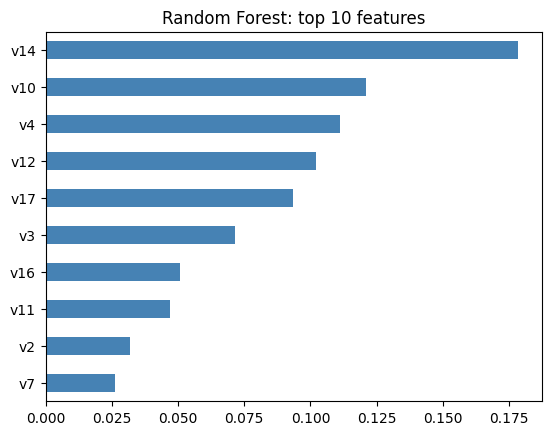

In [17]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
ax = imp.sort_values().plot(kind="barh", color="steelblue")
ax.set_title("Random Forest: top 10 features")
plt.savefig("images/05_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

Bussiness threshold

In [18]:
proba = rf.predict_proba(X_test)[:, 1]
amt = df.loc[X_test.index, "amount"].values   # আসল (স্কেল না করা) পরিমাণ
actual = y_test.values

REVIEW_COST = 5   # ধরে নিলাম: একটা সন্দেহজনক লেনদেন মানুষ দিয়ে যাচাইয়ের খরচ

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    flagged = proba >= t
    missed = (~flagged) & (actual == 1)
    false_alarm = flagged & (actual == 0)
    cost = amt[missed].sum() + REVIEW_COST * flagged.sum()
    rows.append({"threshold": round(t, 2),
                 "frauds_caught": int((flagged & (actual == 1)).sum()),
                 "frauds_missed": int(missed.sum()),
                 "false_alarms": int(false_alarm.sum()),
                 "total_cost": round(cost, 2)})

cost_df = pd.DataFrame(rows)
best = cost_df.loc[cost_df["total_cost"].idxmin()]
print("Best threshold:", best["threshold"])
print("Cost at default 0.5:", cost_df.loc[cost_df["threshold"] == 0.5, "total_cost"].values)
cost_df

Best threshold: 0.15
Cost at default 0.5: [6965.15]


,threshold,frauds_caught,frauds_missed,false_alarms,total_cost
0,0.05,118,24,43,4664.53
1,0.10,115,27,19,4543.60
2,0.15,112,30,13,4523.62
3,0.20,109,33,9,4919.60
4,0.25,109,33,8,4914.60
5,0.30,109,33,7,4909.60
6,0.35,107,35,6,6729.18
7,0.40,106,36,5,6731.49
8,0.45,103,39,4,6974.15
9,0.50,101,41,4,6965.15


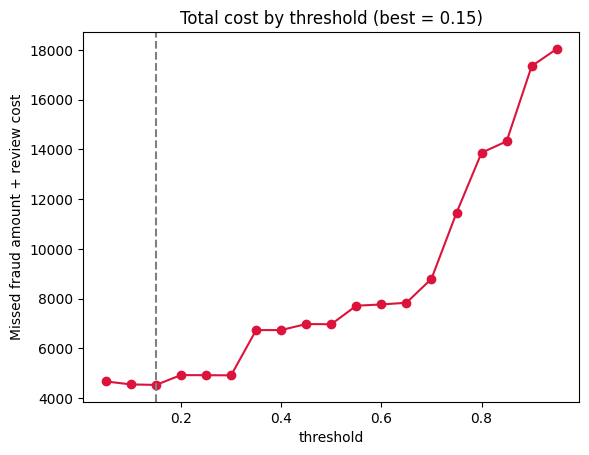

In [19]:
ax = cost_df.plot(x="threshold", y="total_cost", marker="o", legend=False, color="crimson")
ax.axvline(best["threshold"], linestyle="--", color="gray")
ax.set_title(f"Total cost by threshold (best = {best['threshold']})")
ax.set_ylabel("Missed fraud amount + review cost")
plt.savefig("images/06_cost_by_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

CSV

In [21]:
from google.colab import files

scores = pd.DataFrame({"txn_id": df.loc[X_test.index, "txn_id"].values,
                       "fraud_probability": proba.round(4)})
scores.to_csv("txn_risk_scores.csv", index=False)
files.download("txn_risk_scores.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>